In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xarray as xr
import sklearn

In [2]:
data_dir = Path('../data')
data_filename = 'MW_instr2.nc'
data_filepath = Path(data_dir, data_filename)

ds = xr.load_dataset(data_filepath)

In [3]:
ds

<xarray.Dataset> Size: 9MB
Dimensions:     (nb_prof: 1989, freq: 251, pres_level: 91)
Coordinates:
  * nb_prof     (nb_prof) float64 16kB 1.0 2.0 3.0 ... 1.988e+03 1.989e+03
  * freq        (freq) float64 2kB 52.69 52.79 52.89 52.99 ... 454.0 455.0 456.0
  * pres_level  (pres_level) float64 728B 1.0 2.99 5.684 ... 7.336e+04 7.357e+04
Data variables:
    lat         (nb_prof) float64 16kB 43.28 42.84 51.38 ... 82.86 82.41 82.41
    lon         (nb_prof) float64 16kB 42.0 -109.2 69.96 ... -120.0 -78.4 -72.0
    lsm         (nb_prof) float64 16kB 1.0 1.0 1.0 1.0 1.0 ... 0.0 0.0 1.0 1.0
    BT          (freq, nb_prof) float64 4MB 245.2 250.5 243.0 ... 234.5 238.1
    Sigma       (freq) float64 2kB 0.38 0.38 0.38 0.38 ... 2.52 2.52 2.52 2.52
    T           (pres_level, nb_prof) float64 1MB 193.4 181.6 ... 238.4 244.3
    pres        (pres_level, nb_prof) float64 1MB 1.0 1.0 ... 8.541e+04
    hum         (pres_level, nb_prof) float64 1MB 1.987e-06 ... 0.0001778
    Jac_temp    (freq, pres_level) float64 183kB 7.286e-10 ... 0.001268

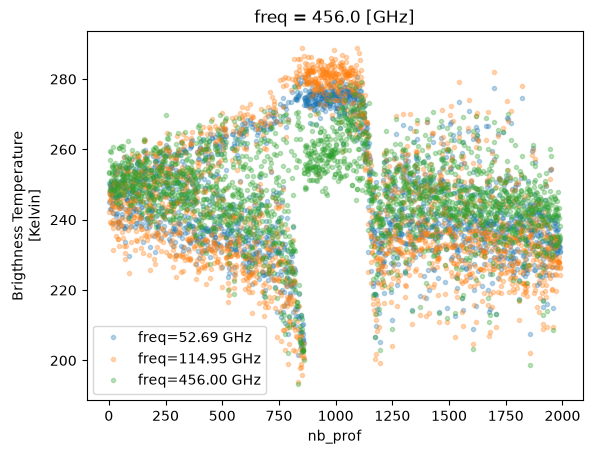

In [25]:
ds['freq']
ds['BT'].isel(freq=0).plot(marker='.', linestyle='', label=f'freq={ds.freq[0].values:.2f} GHz', alpha=0.3)
ds['BT'].isel(freq=100).plot(marker='.', linestyle='', label=f'freq={ds.freq[100].values:.2f} GHz', alpha=0.3)
ds['BT'].isel(freq=250).plot(marker='.', linestyle='', label=f'freq={ds.freq[250].values:.2f} GHz', alpha=0.3)
plt.legend()
plt.show()

# 1. Reduction of the number of channels

## 1a. Ridge and LASSO

In [ ]:
from sklearn.linear_model import RidgeCV, LassoCV, Ridge, Lasso
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler


# choose the features X and the target y
# warning: the y target depends on the task (surface T, whole T profile, humidity)


Ridge  alpha = 1.0 | R² test = 0.9907978487079211
Lasso  alpha = 0.1 | R² test = 0.9870371296313599
Number of kept channels after Lasso: 11 / 251 | Frequencies kept: [ 54.090343  65.18325  113.750343 113.95034  173.310089 173.710083
 174.910095 183.310089 426.763123 449.001068 450.001068]


### Target = surface temperature
Here we choose X for the task of predicting the surface temperature from the brightness temperatures. Later we will focus on predictiong the whole T profile, and then on humidity.

Ridge  alpha = 1.0 | R² test = 0.9907978487079211
Lasso  alpha = 0.1 | R² test = 0.9870371296313599
Number of kept channels after Lasso: 11 / 251 | Frequencies kept: [ 54.090343  65.18325  113.750343 113.95034  173.310089 173.710083
 174.910095 183.310089 426.763123 449.001068 450.001068]


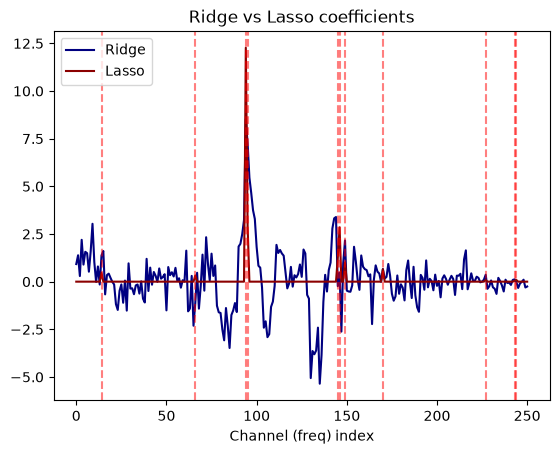

In [56]:
X = ds.BT.values.T # shape (nb_prof, freq) so the channels are the columns
y = ds.T.values[-1, :] # shape (nb_prof, pres_level)
freq = ds.freq.values

X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=0)
sc = StandardScaler().fit(X_tr)
X_tr, X_te = sc.transform(X_tr), sc.transform(X_te)

# Ridge
ridge = Ridge(alpha=1.0).fit(X_tr, y_tr)
print("Ridge  alpha =", ridge.alpha, "| R² test =", ridge.score(X_te, y_te))

# Lasso
lasso = Lasso(alpha=0.1).fit(X_tr, y_tr)

if lasso.coef_.ndim == 2:
    kept = np.flatnonzero(np.any(lasso.coef_ != 0, axis=0))
else:
    kept = np.flatnonzero(lasso.coef_)

print("Lasso  alpha =", lasso.alpha, "| R² test =", lasso.score(X_te, y_te))
print(f"Number of kept channels after Lasso: {len(kept)} / 251 | Frequencies kept:", freq[kept])

plt.plot(ridge.coef_, label="Ridge", c="navy")
plt.plot(lasso.coef_, label="Lasso", c="darkred")
plt.title("Ridge vs Lasso coefficients")
plt.legend()
plt.xlabel("Channel (freq) index")
for i in range(len(kept)):
    plt.axvline(x=kept[i], color='r', linestyle='--', alpha=0.5)
plt.show()

### Target = whole T profile

### Target = humidity

## 1b. PCA

### Target = surface temperature

In [54]:
print(X_tr.shape)
print(ds.T.values[-1, :].shape)

(1591, 251)
(1989,)


Components for 99 % / 99.9 % explained variance : 14 / 87


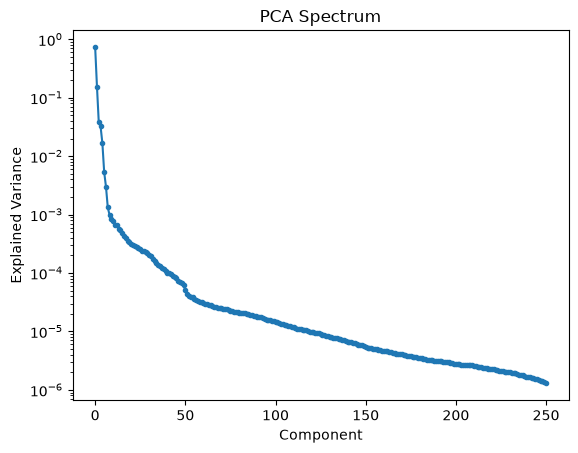

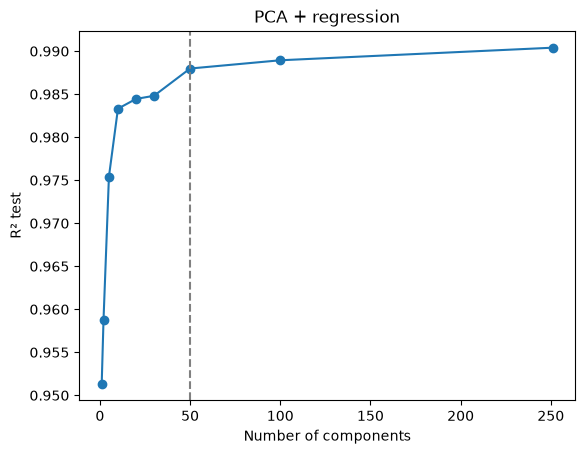

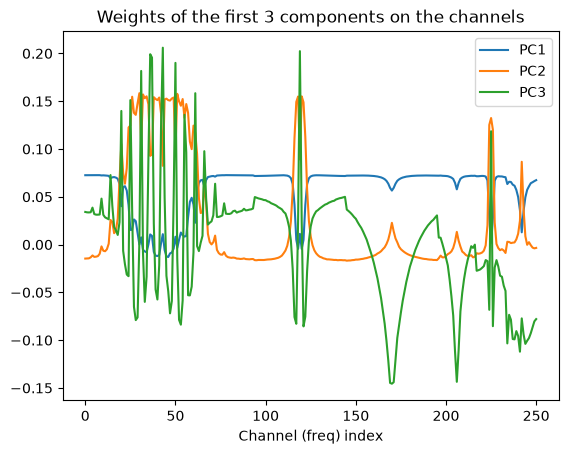

In [80]:
from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression

X = ds.BT.values.T # shape (nb_prof, freq) so the channels are the columns
y = ds.T.values[-1, :] # shape (nb_prof, pres_level)
freq = ds.freq.values

X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=0)
sc = StandardScaler().fit(X_tr)
X_tr, X_te = sc.transform(X_tr), sc.transform(X_te)

# Explained variance ratio
pca = PCA().fit(X_tr)
cumvar = np.cumsum(pca.explained_variance_ratio_)
print("Components for 99 % / 99.9 % explained variance :",
      np.argmax(cumvar >= 0.99) + 1, "/", np.argmax(cumvar >= 0.999) + 1)
plt.semilogy(pca.explained_variance_ratio_, "o-", ms=3)
# plt.semilogy(cumvar, "o-", ms=3)
plt.xlabel("Component"); plt.ylabel("Explained Variance"); plt.title("PCA Spectrum")
plt.show()

# Regression on the first k components, then R² as a function of k
ks = [1, 2, 5, 10, 20, 30, 50, 100, 251]
r2 = []
for k in ks:
    Z_tr = pca.transform(X_tr)[:, :k]
    Z_te = pca.transform(X_te)[:, :k]
    r2.append(LinearRegression().fit(Z_tr, y_tr).score(Z_te, y_te))
plt.plot(ks, r2, "o-"); plt.axvline(50, ls="--", c="grey")
plt.xlabel("Number of components"); plt.ylabel("R² test"); plt.title("PCA + regression")
plt.show()

# What are the weights of the first components on the channels?
top = 3
for i in range(top):
    plt.plot(pca.components_[i], label=f"PC{i+1}")
plt.xlabel("Channel (freq) index"); plt.title(f"Weights of the first {top} components on the channels"); plt.legend()
plt.show()

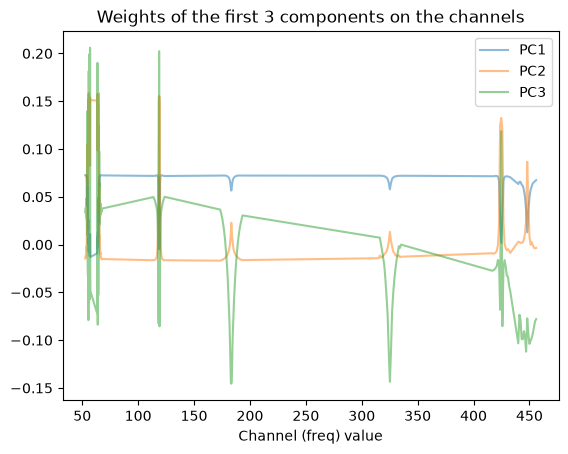

In [84]:
top = 3
for i in range(top):
    plt.plot(freq, pca.components_[i], label=f"PC{i+1}", alpha=0.5)
plt.xlabel("Channel (freq) value"); plt.title(f"Weights of the first {top} components on the channels"); plt.legend()
plt.show()

### Target = whole T profile

### Target = humidity